# Practice 1. Everything you need on one page

Industrial AI, KBTU. A reference for `practice_1.ipynb`.

Every example below runs on a few lines of made-up data, so this notebook opens in a second
and downloads nothing. Copy the patterns and swap in the pump data.

`inclass_work_2.ipynb` shows why each step is needed. This notebook shows how to write it.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2


## 1. The file

Kaggle `nphantawee/pump-sensor-data`: one water pump, five months, one row per minute.

| column | what |
|---|---|
| `timestamp` | 2018-04-01 00:00 to 2018-08-31 23:59 |
| `sensor_00` … `sensor_51` | 52 unlabelled sensors; nobody wrote down what they measure |
| `machine_status` | `NORMAL` / `BROKEN` / `RECOVERING` |

`BROKEN` marks the minute the pump was declared failed. The failure period is the
`RECOVERING` block after it.

The practice loads the file with this; no Kaggle account or token is needed:

```python
def load_pump():
    path = next(dataset_folder("pump_sensor").rglob("*.csv"))
    df = pd.read_csv(path, parse_dates=["timestamp"])
    return df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])

pump = load_pump()
SENSORS = [c for c in pump.columns if c.startswith("sensor_")]
```

The first run downloads 37 MB (124 MB unpacked) and caches it. The second run is instant.

## 2. Looking at a table

Our toy table for the rest of the notebook.

In [2]:
demo = pd.DataFrame({
    "timestamp": pd.date_range("2018-04-01 00:00", periods=8, freq="1min"),
    "sensor_a":  [2.4, 2.5, np.nan, np.nan, 2.6, 2.6, 2.6, 90.0],
    "sensor_b":  [600, 610, 605, 615, 608, 612, 611, 609.0],
    "status":    ["NORMAL"]*6 + ["BROKEN", "RECOVERING"],
})
NUM = ["sensor_a", "sensor_b"]
demo

,timestamp,sensor_a,sensor_b,status
0,2018-04-01 00:00:00,2.400,600.000,NORMAL
1,2018-04-01 00:01:00,2.500,610.000,NORMAL
2,2018-04-01 00:02:00,NaN,605.000,NORMAL
3,2018-04-01 00:03:00,NaN,615.000,NORMAL
4,2018-04-01 00:04:00,2.600,608.000,NORMAL
5,2018-04-01 00:05:00,2.600,612.000,NORMAL
6,2018-04-01 00:06:00,2.600,611.000,BROKEN
7,2018-04-01 00:07:00,90.000,609.000,RECOVERING


In [3]:
print(demo.shape)                      # (rows, columns)
print()
print(demo[NUM].describe().T)          # count / mean / std / min / quartiles / max

(8, 4)

          count    mean    std     min     25%     50%     75%     max
sensor_a  6.000  17.117 35.705   2.400   2.525   2.600   2.600  90.000
sensor_b  8.000 608.750  4.590 600.000 607.250 609.500 611.250 615.000


Read `describe()` as four questions. Is `count` the same everywhere (if not, there are gaps)?
Are `min` and `max` physically possible? Are `mean` and `50%` far apart (skew)? Is `std` zero
(a stuck tag)?

In [4]:
print(demo["status"].value_counts())                # how many of each label
print()
print(demo["status"].value_counts(normalize=True))  # as a share, needed in Task 4
print()
print(demo.nunique())                               # 1 unique value = a constant column

status
NORMAL        6
BROKEN        1
RECOVERING    1
Name: count, dtype: int64

status
NORMAL       0.750
BROKEN       0.125
RECOVERING   0.125
Name: proportion, dtype: float64

timestamp    8
sensor_a     4
sensor_b     8
status       3
dtype: int64


## 3. Masks

A mask is a `True`/`False` Series of the same length as the column. Everything in Task 4 is
built from masks.

In [5]:
big = demo["sensor_a"] > 3

print(big.to_string(), "\n")
print("how many :", big.sum())          # True counts as 1
print("share    :", big.mean())
print("rows     :", demo.loc[big, "sensor_a"].tolist())
print("the rest :", demo.loc[~big, "sensor_a"].tolist())   # ~ means NOT

0    False
1    False
2    False
3    False
4    False
5    False
6    False
7     True 

how many : 1
share    : 0.125
rows     : [90.0]
the rest : [2.4, 2.5, nan, nan, 2.6, 2.6, 2.6]


In [6]:
# combine masks with & (and) and | (or). The brackets are required.
not_normal = demo["status"] != "NORMAL"
print("big AND not normal:", (big & not_normal).sum())
print("big OR  not normal:", (big | not_normal).sum())

# keep the mask as a feature instead of deleting rows
demo["a_is_high"] = big.astype(int)
print()
print(demo[["sensor_a", "a_is_high"]].to_string())

big AND not normal: 1
big OR  not normal: 2

   sensor_a  a_is_high
0     2.400          0
1     2.500          0
2       NaN          0
3       NaN          0
4     2.600          0
5     2.600          0
6     2.600          0
7    90.000          1


## 4. Missing values

In [7]:
s = demo["sensor_a"]

print(pd.DataFrame({
    "raw":         s,
    "ffill":       s.ffill(),                              # hold the last known value
    "interpolate": s.interpolate(),                        # straight line across the gap
    "both ends":   s.interpolate(limit_direction="both"),  # also fills a leading NaN
}).to_string())

print("\nmissing per column:")
print(demo.isna().sum().to_string())
print("\nas a share, %:")
print((demo.isna().mean() * 100).round(2).to_string())

     raw  ffill  interpolate  both ends
0  2.400  2.400        2.400      2.400
1  2.500  2.500        2.500      2.500
2    NaN  2.500        2.533      2.533
3    NaN  2.500        2.567      2.567
4  2.600  2.600        2.600      2.600
5  2.600  2.600        2.600      2.600
6  2.600  2.600        2.600      2.600
7 90.000 90.000       90.000     90.000

missing per column:
timestamp    0
sensor_a     2
sensor_b     0
status       0
a_is_high    0

as a share, %:
timestamp    0.000
sensor_a    25.000
sensor_b     0.000
status       0.000
a_is_high    0.000


`ffill` holds, `interpolate` draws a slope. Neither fills a gap at the very start, where there
is nothing to the left, so finish with `limit_direction="both"` or `.bfill()`.

Before you fill anything, look at the shape of the gaps. Scattered single samples are safe to
interpolate. A block of hours is not: a straight line across it invents hours of data. The
missingness map in section 8 tells the two apart.

## 5. Duplicates and stuck tags

In [8]:
# duplicated() compares whole rows; subset= compares only those columns
print("duplicate rows        :", demo.duplicated().sum())
print("duplicate sensor pairs:", demo.duplicated(subset=NUM).sum())
print("duplicate timestamps  :", demo.duplicated(subset="timestamp").sum())

duplicate rows        : 0
duplicate sensor pairs: 0
duplicate timestamps  : 0


In [9]:
# The run-length idiom, needed in Task 2.
v = pd.Series([1, 1, 1, 2, 2, 3, 3, 3, 3, 3])

new_run = v.diff() != 0        # True where the value changes
run_id = new_run.cumsum()      # running sum: every run gets its own id

print(pd.DataFrame({"v": v, "new_run": new_run, "run_id": run_id}).to_string())
print("\nlongest run:", v.groupby(run_id).size().max())

   v  new_run  run_id
0  1     True       1
1  1    False       1
2  1    False       1
3  2     True       2
4  2    False       2
5  3     True       3
6  3    False       3
7  3    False       3
8  3    False       3
9  3    False       3

longest run: 5


## 6. Time

`set_index("timestamp")` first: everything below needs a time index.

In [10]:
ts = demo.set_index("timestamp")

# is the clock regular? every step should be the same
print(ts.index.to_series().diff().value_counts().to_string())

# asfreq puts the index on a fixed grid; missing minutes appear as NaN.
# resample squashes several rows into one. A different operation.
every_3min = ts["sensor_b"].resample("3min").agg(["mean", "max", "std"])
print()
print(every_3min.round(2).to_string())

timestamp
0 days 00:01:00    7

                       mean     max   std
timestamp                                
2018-04-01 00:00:00 605.000 610.000 5.000
2018-04-01 00:03:00 611.670 615.000 3.510
2018-04-01 00:06:00 610.000 611.000 1.410


A missing row is not a `NaN`. `isna()` cannot see it, because there is nothing to test. You
catch it by comparing the number of rows with the number of minutes in the span.

`rolling(k)` counts samples, not minutes. On a complete grid the two are the same.

In [11]:
b = ts["sensor_b"]
print(pd.DataFrame({
    "raw":      b,
    "mean 3":   b.rolling(3).mean().round(2),
    "median 3": b.rolling(3, center=True).median(),   # centred: uses both sides
}).to_string())

                        raw  mean 3  median 3
timestamp                                    
2018-04-01 00:00:00 600.000     NaN       NaN
2018-04-01 00:01:00 610.000     NaN   605.000
2018-04-01 00:02:00 605.000 605.000   610.000
2018-04-01 00:03:00 615.000 610.000   608.000
2018-04-01 00:04:00 608.000 609.330   612.000
2018-04-01 00:05:00 612.000 611.670   611.000
2018-04-01 00:06:00 611.000 610.330   611.000
2018-04-01 00:07:00 609.000 610.670       NaN


Moving average against median filter: a single spike spoils $k$ samples of the average and none
of the median. Use the median when you remove spikes.

## 7. The maths

### Outliers: three rules, three answers

**3-sigma.** Flag $x$ outside $[\mu - 3\sigma,\ \mu + 3\sigma]$. On a normal distribution this
band holds 99.73 %, so the rule flags 0.27 %. Its weakness: $\mu$ and $\sigma$ are computed
from the data including the outliers, so a long tail inflates $\sigma$ and the rule goes quiet.

**IQR (Tukey).** With $\mathrm{IQR} = Q_3 - Q_1$, flag $x$ outside

$$[\,Q_1 - 1.5\,\mathrm{IQR},\ \ Q_3 + 1.5\,\mathrm{IQR}\,]$$

Quartiles do not care how far the far points are, so the rule is robust. It flags about 0.70 %
of a normal distribution and far more of a skewed one.

**Robust z.** With $\mathrm{MAD} = \mathrm{median}\,|x - \mathrm{med}|$,

$$z = \frac{0.6745\,(x - \mathrm{med})}{\mathrm{MAD}}, \qquad \text{flag } |z| > 3.5$$

The 0.6745 makes $z$ agree with an ordinary z-score on normal data.

Which to trust: check the skew. Near zero, the rules agree. On a skewed column, believe IQR.

### Scaling: three formulas

$$\text{min-max: } x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
\qquad
\text{z-score: } x' = \frac{x - \mu}{\sigma}
\qquad
\text{robust: } x' = \frac{x - \mathrm{med}}{Q_3 - Q_1}$$

Min-max takes its two numbers from the most extreme values of the column, so one stuck register
destroys it. Default to the z-score.

### PCA: why each step

The goal is the direction of largest spread. Project the data on a unit vector $\mathbf{w}$;
the variance of the projections is $\mathbf{w}^{\top} \mathbf{C}\, \mathbf{w}$. Maximise that
under $\lVert\mathbf{w}\rVert = 1$ and you get

$$\mathbf{C}\, \mathbf{w} = \lambda\, \mathbf{w}$$

so the eigenvectors are the answer to the question, and $\lambda = \mathbf{w}^{\top}
\mathbf{C}\,\mathbf{w}$: each eigenvalue is the variance along its own axis. That is why
$\lambda_i / \sum_j \lambda_j$ is the share of variance.

The recipe:

1. standardise: variance carries units, and without this the sensor with the biggest numbers
   wins and you get a PCA of the units;
2. covariance $\mathbf{C} = \frac{1}{n-1} \mathbf{Z}^{\top} \mathbf{Z}$;
3. `eigh`, not `eig`: $\mathbf{C}$ is symmetric, so the eigenvectors come out orthogonal and
   the components are uncorrelated;
4. sort in descending order: `eigh` returns the eigenvalues smallest first;
5. ratio $r_i = \lambda_i / \sum_j \lambda_j$;
6. project, $\mathbf{P} = \mathbf{Z}\mathbf{V}$. Column $i$ of $\mathbf{P}$ is what you plot.

A free check: after standardising, $\sum_i \lambda_i = p$, the number of features, because the
sum of the eigenvalues is the trace of $\mathbf{C}$ and every column contributes a variance of
exactly 1.

For the check to come out at exactly $p$, divide by `X.std(axis=0, ddof=1)` to match the
$1/(n-1)$ in $\mathbf{C}$. `StandardScaler` and the practice skeleton use `ddof=0`, which scales
every eigenvalue by $n/(n-1)$. At $n = 220\,320$ that is invisible, and the ratios are the same
either way.

### PCA the other way: the Gram matrix

The same data from the other side: $\mathbf{G} = \mathbf{Z} \mathbf{Z}^{\top}$, which is
$n \times n$ instead of $p \times p$. Eigen-decompose it, then

$$r_i = \frac{\mu_i}{\sum_j \mu_j}, \qquad \mathbf{P} = \mathbf{U}\sqrt{\mathbf{M}}$$

In numpy the scores are `U * np.sqrt(mu)`.

Both routes give the same components, because the SVD $\mathbf{Z} =
\mathbf{U}\mathbf{S}\mathbf{V}^{\top}$ gives

$$\mathbf{Z}^{\top}\mathbf{Z} = \mathbf{V} \mathbf{S}^2 \mathbf{V}^{\top}, \qquad \mathbf{Z} \mathbf{Z}^{\top} = \mathbf{U} \mathbf{S}^2 \mathbf{U}^{\top}$$

one $\mathbf{S}$, two sides. Expect $\mu_i = (n-1)\lambda_i$, a constant that cancels in the
ratios, and expect $\mathbf{G}$ to have at most $\min(n-1, p)$ non-zero eigenvalues, since its
rank cannot exceed the rank of $\mathbf{Z}$. The signs of eigenvectors are arbitrary in both
routes, so a mirrored plot is not a mistake.

In [12]:
# the whole of PCA, on the toy table
X = demo[NUM].interpolate(limit_direction="both").to_numpy(float)
n = len(X)

Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)    # 1. standardise
C = Z.T @ Z / (n - 1)                        # 2. covariance
lam, vec = np.linalg.eigh(C)                 # 3. eigh
order = np.argsort(lam)[::-1]                # 4. sort in descending order
lam, vec = lam[order], vec[:, order]
ratio = lam / lam.sum()                      # 5. share of variance
P = Z @ vec                                  # 6. project

print("eigenvalues :", lam.round(4))
print("sum         :", lam.sum().round(4), " = number of features")
print("diag of C   :", np.diag(C).round(4), " = all ones, because Z is standardised")
print("ratio       :", ratio.round(4))
print("var of PC1  :", P[:, 0].var(ddof=1).round(4), " = lambda_1")

eigenvalues : [1.0237 0.9763]
sum         : 2.0  = number of features
diag of C   : [1. 1.]  = all ones, because Z is standardised
ratio       : [0.5118 0.4882]
var of PC1  : 1.0237  = lambda_1


## 8. The four plots you will need

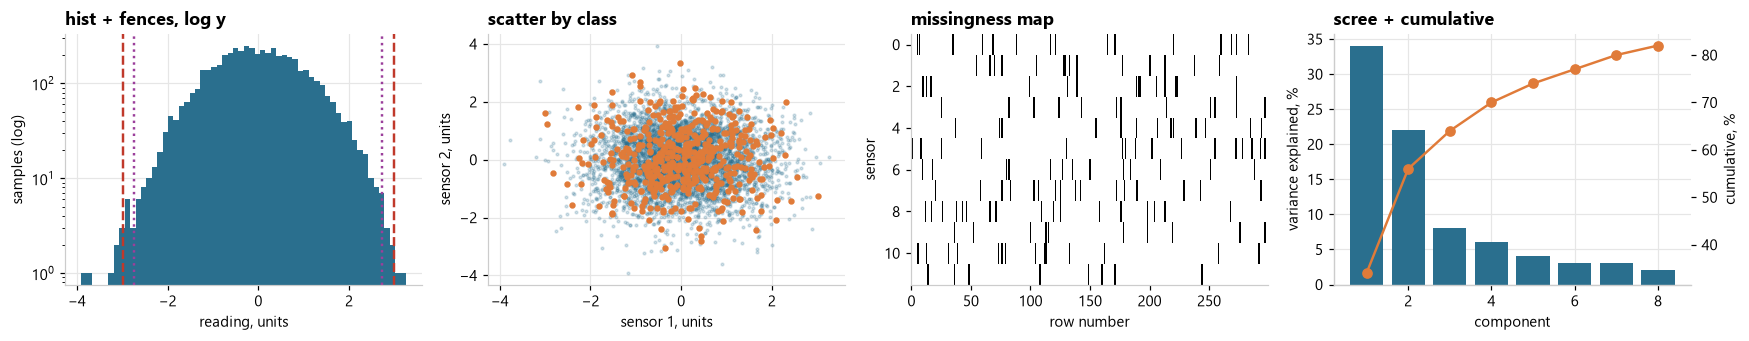

In [13]:
rng = np.random.default_rng(0)
x = rng.normal(0, 1, 5000)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))

# (a) histogram with both fences on it
mu, sd = x.mean(), x.std()
q1, q3 = np.percentile(x, [25, 75])
ax[0].hist(x, bins=60, color=BLUE)
iqr = q3 - q1
for v in (mu - 3 * sd, mu + 3 * sd):
    ax[0].axvline(v, color=RED, ls="--")
for v in (q1 - 1.5 * iqr, q3 + 1.5 * iqr):
    ax[0].axvline(v, color=PURPLE, ls=":")
ax[0].set_yscale("log")                       # or the tails are invisible
ax[0].set(xlabel="reading, units", ylabel="samples (log)", title="hist + fences, log y")

# (b) scatter coloured by class: draw the big group first, small and faint
lab = rng.random(5000) < 0.1
ax[1].scatter(x[~lab], rng.normal(size=(~lab).sum()), s=3, c=BLUE, alpha=0.2)
ax[1].scatter(x[lab], rng.normal(size=lab.sum()), s=10, c=ORANGE)
ax[1].set(xlabel="sensor 1, units", ylabel="sensor 2, units", title="scatter by class")

# (c) missingness map: black = no value
mask = rng.random((12, 300)) < 0.05
ax[2].imshow(mask, aspect="auto", cmap="Greys", interpolation="nearest")
ax[2].grid(False)
ax[2].set(xlabel="row number", ylabel="sensor", title="missingness map")

# (d) scree with the cumulative curve on a second axis
r = np.array([34, 22, 8, 6, 4, 3, 3, 2])
ax[3].bar(range(1, 9), r, color=BLUE)
ax2 = ax[3].twinx()
ax2.plot(range(1, 9), r.cumsum(), color=ORANGE, marker="o")
ax2.grid(False)
ax[3].set(xlabel="component", ylabel="variance explained, %", title="scree + cumulative")
ax2.set(ylabel="cumulative, %")

fig.tight_layout()
plt.show()

Patterns worth copying: `set_yscale("log")` on a histogram, or the tail you are hunting is one
pixel tall; draw the majority class first with `s=3, alpha=0.2` so that the minority stays
visible; `imshow(df.isna().to_numpy().T)` for the missingness map; `twinx()` for the cumulative
curve.

Every figure needs axis labels with units and a title that says what to look at.

## 9. Task by task

| task | what you need from this page |
|---|---|
| 1 | `shape`, `info`, `value_counts`, `index.diff().value_counts()` |
| 2 | `nunique`, `duplicated(subset=...)`, the run-length idiom (§5) |
| 3 | `isna().mean()`, missingness map (§8c), `interpolate(limit_direction="both")` |
| 4 | masks (§3), the three rules (§7), hist + fences (§8a), `value_counts(normalize=True)` |
| 5 | `set_index`, `resample("1h").agg([...])`, `axvline` at the breakdown |
| 6 | the three scaler formulas (§7), boxplots, `np.percentile` |
| 7 | the six PCA steps (§7), scree (§8d), scatter by class (§8b) |
| 8 | the Gram route (§7), `time.perf_counter()`, `np.allclose`, `np.abs` for the sign |

## 10. Things that cost marks

- Deleting flagged rows. You are looking for breakdowns, and a breakdown is an outlier. Flag
  with a 0/1 column and keep every row. Delete only when you can name the physical reason why
  the value is impossible.
- Interpolating across long gaps without saying what that invents.
- A number with no sentence. Half of every task's mark is the written answer: state what you
  found, with the figure in it.
- A claim your own figure contradicts. If the plot shows no trend before the breakdown, write
  that there is none.
- Fitting a scaler on everything. `fit` on the training rows, `transform` on both. Test means of
  exactly zero mean you fitted on the test set.
- "PCA reduced the dimensionality to 2" under a figure whose axis labels show how much variance
  the two components actually keep.